# Démonstration V2 : décisions, exécutions et coûts

Marché synthétique. Cette démonstration explique les mécanismes ; le second notebook examine le protocole et les incertitudes. Les résultats V1 fondés sur `sqrt(q / volume_journalier_prévu)` sont remplacés.


In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from execution_cost_analytics.data import generate_market_data
from execution_cost_analytics.experiment import run_experiment
from execution_cost_analytics.reporting import write_report
from execution_cost_analytics.strategies import pov_schedule, twap_schedule, vwap_schedule

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists()

## 1. Retrouver les quantités à la main

TWAP et VWAP construisent un calendrier entier. La fonction POV ci-dessous illustre la participation à un flux ; l'expérience utilise le moteur séquentiel et les quantités effectivement exécutées.


In [2]:
pd.DataFrame(
    {
        "TWAP_101": twap_schedule(101, 4),
        "VWAP_100": vwap_schedule(100, [0.1, 0.2, 0.3, 0.4]),
        "POV_100_a_10pct": pov_schedule(100, [100, 200, 100, 100], 0.1),
    }
)

,TWAP_101,VWAP_100,POV_100_a_10pct
0,26,10,10
1,25,20,20
2,25,30,10
3,25,40,10


## 2. Simuler quatre politiques sur les mêmes séances

La prévision utilise les 20 journées antérieures. ADAPTIVE ajoute au plan prévu un rattrapage du retard observé avec les fills passés. Le moteur applique ensuite capacité et coût réalisés. La démonstration prend sa référence à la dernière observation de la veille ; l'étude V2 prend décision = arrivée pour isoler l'exécution intraday.


,strategy,evaluated_sessions,mean_fill_rate,completion_probability,mean_cost_bps,std_cost_bps,mean_vwap_slippage_bps
0,TWAP,10,1.0000,1.0,-3.0742,105.0869,3.6754
1,VWAP,10,1.0000,1.0,-3.4882,103.6242,3.2735
2,POV,10,0.6015,0.0,-1.3477,138.0687,3.0930
3,ADAPTIVE,10,1.0000,1.0,-3.4882,103.6242,3.2735


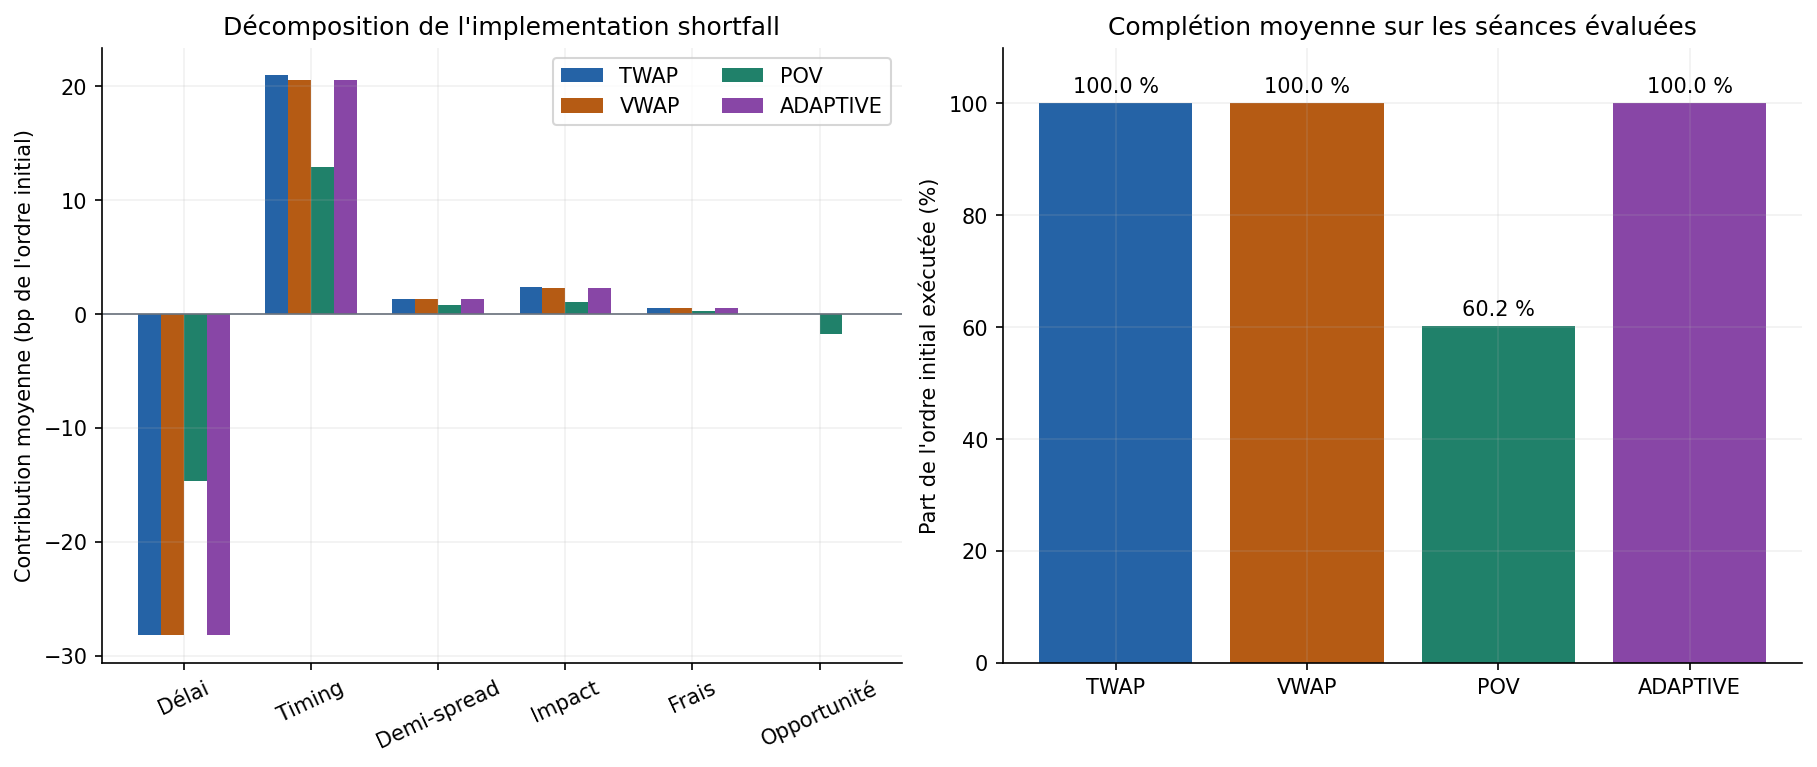

In [3]:
market = generate_market_data(n_days=40, n_buckets=26, seed=42)
result = run_experiment(market, quantity=50_000, train_days=30, lookback=20)
result.metadata.update({"data_type": "synthetic", "seed": 42, "generated_days": 40})
write_report(result, ROOT / "reports")
display(result.aggregate_summary.round(4))
assert (result.forecast_metrics["last_training_session"] < result.forecast_metrics["session"]).all()
assert result.summary["reconciliation_error"].abs().max() < 1e-6
display(Image(filename=str(ROOT / "reports/figures/cost_decomposition.png")))

## 3. Coût local et information disponible

L'impact temporaire par unité vaut `prix × eta × sigma × (q / volume_local_réalisé)^alpha`. La prévision sert à décider, pas à facturer une liquidité artificielle. Dans un cas contrôlé, subdiviser quantité et volume proportionnellement conserve la participation et le coût. Ce contrôle ne calibre pas le modèle économiquement.


,impact_model,n_buckets,total_quantity,total_market_volume,total_cost_bps,impact_cost_bps,max_participation,passed
0,sqrt,26,10400,104000,4.662486,3.162278,0.1,True
1,sqrt,52,10400,104000,4.662486,3.162278,0.1,True
2,sqrt,104,10400,104000,4.662486,3.162278,0.1,True
3,linear,26,10400,104000,4.662486,3.162278,0.1,True
4,linear,52,10400,104000,4.662486,3.162278,0.1,True
5,linear,104,10400,104000,4.662486,3.162278,0.1,True


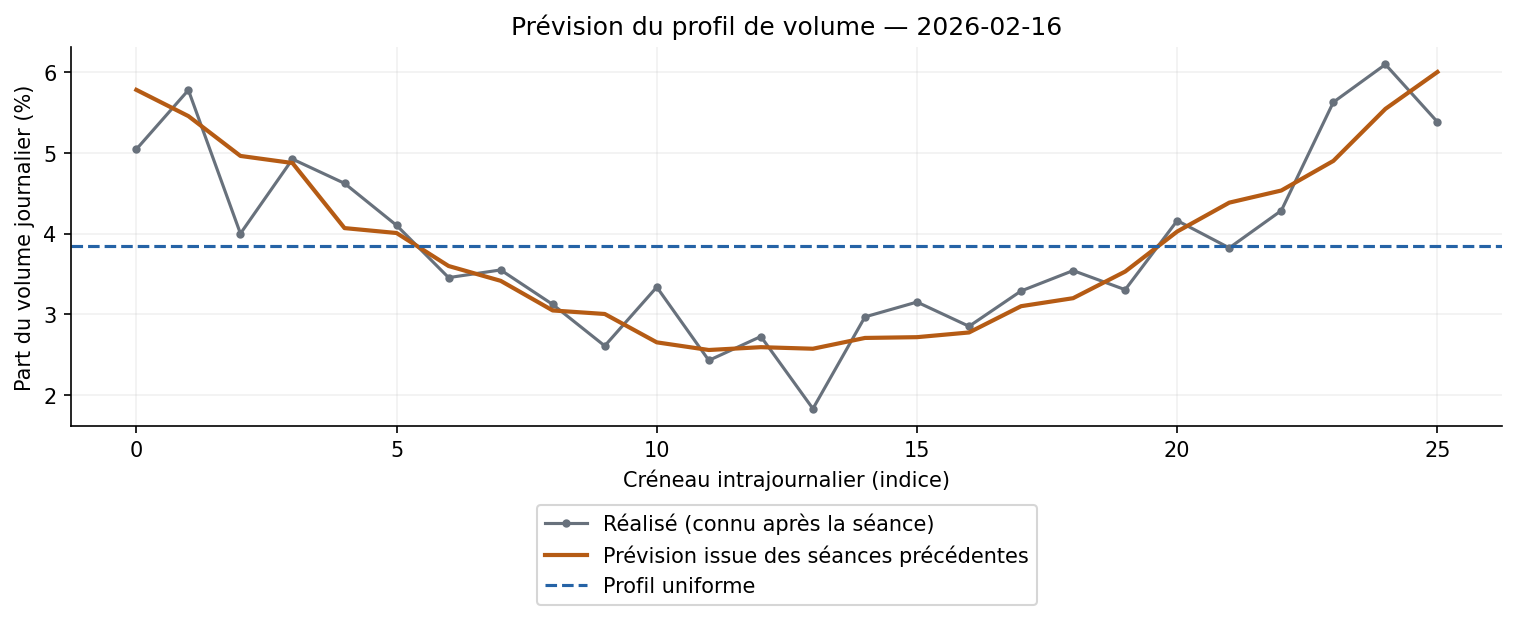

In [4]:
from execution_cost_analytics.study import grid_invariance_check

grid = grid_invariance_check()
display(grid)
assert grid["passed"].all()
display(Image(filename=str(ROOT / "reports/figures/volume_forecast.png")))

## 4. Reprendre le développement

Le guide `docs/GUIDE_PAS_A_PAS.md` relie chaque fonction à un exemple et un test. Pour tester la règle terminale : `demo --deadline-mode common_deadline --output-dir outputs/deadline`. Les derniers `ceil(20 % × B)` créneaux reçoivent la même instruction pour toutes les méthodes : demander le reliquat sous un plafond de 40 %, avec spread, impact et frais. Un manque de capacité laisse l'ordre incomplet.
